In [23]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf


In [24]:
# Load the datasets
df_train = pd.read_csv("train_data-1.csv")
df_test  = pd.read_csv("test_data-1.csv")
df_site_const = pd.read_csv("site_const_data-1-1.csv")

# Rename columns to use underscores
df_train = df_train.rename(columns = {'store.number':'store_number',
                               'annual.profit': 'annual_profit',
                               'agg.inc':'agg_inc',
                               'col.grad':'col_grad'})
df_test = df_test.rename(columns = {'store.number':'store_number',
                               'annual.profit': 'annual_profit',
                               'agg.inc':'agg_inc',
                              'col.grad':'col_grad'})
df_site_const = df_site_const.rename(columns = {'store.number':'store_number',
                               'annual.profit': 'annual_profit',
                               'agg.inc':'agg_inc',
                              'col.grad':'col_grad'})



In [7]:
# Calculate the percentage of data in training set
total_rows = df_train.shape[0] + df_test.shape[0]
train_percentage = (df_train.shape[0] / total_rows) * 100

print(f"Training data: {len(df_train)} rows")
print(f"Test data: {len(df_test)} rows")
print(f"Total data: {total_rows} rows")
print(f"Percentage of data in training: {train_percentage:.2f}%")


Training data: 374 rows
Test data: 85 rows
Total data: 459 rows
Percentage of data in training: 81.48%


In [8]:
# b
# Training data is used to build the model
# Test data is used to evaluate the model


In [9]:
# Run linear regression using OLS with formula
# Assuming 'annual_profit' is the target variable and other columns are features
linear_regression_1 = smf.ols('annual_profit ~ agg_inc + col_grad + com60 + sqft', data=df_train)
linear_regression_results_1 = linear_regression_1.fit()

# Print model summary
print(linear_regression_results_1.summary())
# Models with intecept and without intercept are acceptable. 


                            OLS Regression Results                            
Dep. Variable:          annual_profit   R-squared:                       0.786
Model:                            OLS   Adj. R-squared:                  0.784
Method:                 Least Squares   F-statistic:                     339.1
Date:                Fri, 30 Oct 2026   Prob (F-statistic):          3.73e-122
Time:                        06:18:44   Log-Likelihood:                -5107.5
No. Observations:                 374   AIC:                         1.022e+04
Df Residuals:                     369   BIC:                         1.024e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    8.36e+04   4.11e+04      2.035      0.0

In [10]:
#Complete Linear Regression Equation:
#annual_profit = 83597.0925 + 0.0028073454 × agg_inc + 383.3631 × sqft + 346821.1387 × col_grad + 218265.7646 × com60


In [11]:
# Predict annual profitability for the specified Milagro store
# Given values:
# - agg_inc: $100,000,000
# - sqft: 800 square feet  
# - col_grad: 0.30 (30%)
# - com60: 0.10 (10%)

# Create a dictionary with the input values
new_store_data = {
    'agg_inc': 100000000,
    'col_grad': 0.30,
    'com60': 0.10,
    'sqft': 800
}

# Make prediction using the fitted model
predicted_profit = linear_regression_results_1.predict(new_store_data)

print(f"Predicted annual profit for the Milagro store: ${predicted_profit[0]:,.2f}")


Predicted annual profit for the Milagro store: $796,894.99


In [12]:
# Evaluate model quality by computing SST and SSE

# a) R-squared value on training data
train_predictions = linear_regression_results_1.predict(df_train)
train_actual = df_train['annual_profit']

# Calculate SST (Total Sum of Squares) for training data
train_mean = train_actual.mean()
train_sst = ((train_actual - train_mean) ** 2).sum()

# Calculate SSE (Sum of Squared Errors) for training data
train_sse = ((train_actual - train_predictions) ** 2).sum()

# Calculate R-squared for training data
train_r2 = 1 - (train_sse / train_sst)
print(f"Training data:")
print(f"  SST: {train_sst:,.2f}")
print(f"  SSE: {train_sse:,.2f}")
print(f"  R-squared: {train_r2:.4f}")

# b) R-squared value on test data
test_predictions = linear_regression_results_1.predict(df_test)
test_actual = df_test['annual_profit']

# Calculate SST (Total Sum of Squares) for test data
test_sst = ((test_actual - train_mean) ** 2).sum()

# Calculate SSE (Sum of Squared Errors) for test data
test_sse = ((test_actual - test_predictions) ** 2).sum()

# Calculate R-squared for test data
test_r2 = 1 - (test_sse / test_sst)
print(f"\nTest data:")
print(f"  SST: {test_sst:,.2f}")
print(f"  SSE: {test_sse:,.2f}")
print(f"  R-squared: {test_r2:.4f}")

# Model Performance Summary
print(f"\nModel Performance Summary:")
print(f"Training R²: {train_r2:.4f}")
print(f"Test R²: {test_r2:.4f}")




Training data:
  SST: 74,475,506,688,120.09
  SSE: 15,927,103,626,083.47
  R-squared: 0.7861

Test data:
  SST: 10,624,208,976,613.77
  SSE: 2,973,254,651,142.02
  R-squared: 0.7201

Model Performance Summary:
Training R²: 0.7861
Test R²: 0.7201


In [13]:
# Test statistical significance of predictors
# Extract p-values from the model
p_values = linear_regression_results_1.pvalues[1:]  # Exclude intercept. Answer is acceptable if you included intercept as well. 
print("Statistical Significance Analysis (α = 0.05)")
print("=" * 60)
print("\na) Statistically Significant Variables at 5% level:")
significant_vars = p_values[p_values < 0.05]
for var, pval in significant_vars.items():
    stars = '***' if pval < 0.001 else '**' if pval < 0.01 else '*'
    print(f"   {var:12s}: p-value = {pval:.4f} {stars}")

print(f"\nb) Most Statistically Significant (smallest p-value):")
min_var = p_values.idxmin()
print(f"   {min_var}: p-value = {p_values[min_var]:.6f}")
print(f"   (This variable has the strongest evidence against the null hypothesis)")

print(f"\nc) Least Statistically Significant (largest p-value, but < 0.05):")
significant_only = p_values[p_values < 0.05]
max_var = significant_only.idxmax()
print(f"   {max_var}: p-value = {p_values[max_var]:.4f}")
print(f"   (This variable is still significant but has the weakest evidence)")



Statistical Significance Analysis (α = 0.05)

a) Statistically Significant Variables at 5% level:
   agg_inc     : p-value = 0.0000 ***
   col_grad    : p-value = 0.0023 **
   com60       : p-value = 0.0269 *
   sqft        : p-value = 0.0000 ***

b) Most Statistically Significant (smallest p-value):
   agg_inc: p-value = 0.000000
   (This variable has the strongest evidence against the null hypothesis)

c) Least Statistically Significant (largest p-value, but < 0.05):
   com60: p-value = 0.0269
   (This variable is still significant but has the weakest evidence)


Numerical predictor variables (10):
['agg_inc', 'sqft', 'col_grad', 'com60', 'lci', 'nearcomp', 'nearmil', 'freestand', 'gini', 'housemed']

CORRELATION MATRIX
           agg_inc   sqft  col_grad  com60    lci  nearcomp  nearmil  \
agg_inc      1.000  0.512     0.670 -0.239 -0.315    -0.148    0.160   
sqft         0.512  1.000     0.353 -0.055 -0.300    -0.074    0.122   
col_grad     0.670  0.353     1.000 -0.224 -0.314    -0.182    0.065   
com60       -0.239 -0.055    -0.224  1.000 -0.004     0.025    0.038   
lci         -0.315 -0.300    -0.314 -0.004  1.000     0.071   -0.115   
nearcomp    -0.148 -0.074    -0.182  0.025  0.071     1.000   -0.110   
nearmil      0.160  0.122     0.065  0.038 -0.115    -0.110    1.000   
freestand    0.173  0.150     0.166 -0.032 -0.220     0.104    0.211   
gini         0.069  0.111     0.001 -0.035 -0.105     0.112   -0.012   
housemed     0.486  0.177     0.547 -0.106 -0.152    -0.175    0.032   

           freestand   gini  housemed  
agg_inc

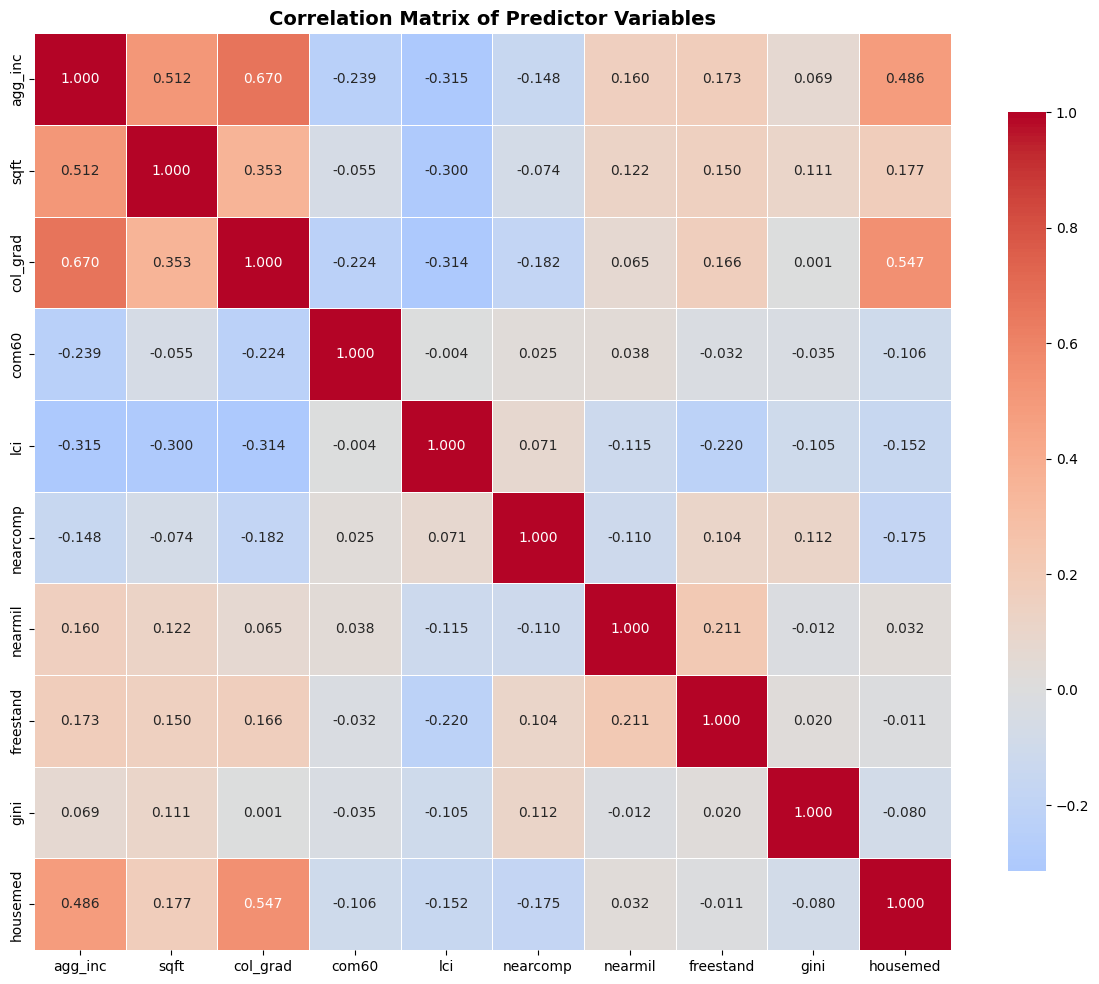

In [14]:
# Compute correlation matrix for numerical predictor variables
# Exclude store_number, annual_profit, and state

# Select numerical columns (exclude store_number, annual_profit, and state)
exclude_cols = ['store_number', 'annual_profit', 'state']
predictor_cols = [col for col in df_train.columns if col not in exclude_cols]

# Get only numerical columns
numerical_predictors = df_train[predictor_cols].select_dtypes(include=[np.number])

print(f"Numerical predictor variables ({len(numerical_predictors.columns)}):")
print(numerical_predictors.columns.tolist())

# Compute correlation matrix
corr_matrix = numerical_predictors.corr()

print("\n" + "="*70)
print("CORRELATION MATRIX")
print("="*70)
print(corr_matrix.round(3))

# Extract upper triangle of correlation matrix (to avoid duplicates)
# Set diagonal to NaN to exclude self-correlations
corr_matrix_upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Stack the correlation matrix and sort by absolute value
correlations = corr_matrix_upper.stack().sort_values(key=abs, ascending=False)

print("\n" + "="*70)
print("a) TOP 3 PAIRS WITH STRONGEST CORRELATIONS")
print("="*70)

# Display top 3 pairs
for i, ((var1, var2), corr_value) in enumerate(correlations.head(3).items(), 1):
    print(f"\n{i}. {var1} & {var2}")
    print(f"   Correlation coefficient: {corr_value:.4f}")
    print(f"   Absolute value: {abs(corr_value):.4f}")

# Optional: Create a heatmap for better visualization
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt='.3f', cmap='coolwarm', center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title('Correlation Matrix of Predictor Variables', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


In [15]:
# Build regression model with ALL 10 variables
# Original 4: agg_inc, col_grad, com60, sqft
# New 6: lci, nearcomp, nearmil, freestand, gini, housemed



# Build the model with all 10 variables
model_full = smf.ols('annual_profit ~ agg_inc + col_grad + com60 + sqft + lci + nearcomp + nearmil + freestand + gini + housemed', 
                 data=df_train).fit()

# Print full model summary
print(model_full.summary())

print("\n" + "="*70)
print("STATISTICAL SIGNIFICANCE ANALYSIS (α = 0.05)")
print("="*70)

# Extract p-values (exclude intercept)
p_values_full = model_full.pvalues[1:]

# Define the 6 new variables
new_variables = ['lci', 'nearcomp', 'nearmil', 'freestand', 'gini', 'housemed']
original_variables = ['agg_inc', 'col_grad', 'com60', 'sqft']

print("\nORIGINAL 4 VARIABLES:")
print("-" * 50)
for var in original_variables:
    if var in p_values_full.index:
        pval = p_values_full[var]
        significance = "✓ Significant" if pval < 0.05 else "✗ Not significant"
        stars = '***' if pval < 0.001 else '**' if pval < 0.01 else '*' if pval < 0.05 else ''
        print(f"  {var:12s}: p-value = {pval:.4f}  {stars:3s}  {significance}")

print("\n" + "="*70)
print("a) NEW 6 VARIABLES - Statistical Significance:")
print("="*70)

significant_new_vars = []
not_significant_new_vars = []

for var in new_variables:
    if var in p_values_full.index:
        pval = p_values_full[var]
        if pval < 0.05:
            significant_new_vars.append((var, pval))
            stars = '***' if pval < 0.001 else '**' if pval < 0.01 else '*'
            print(f"  ✓ {var:12s}: p-value = {pval:.4f}  {stars}  [SIGNIFICANT]")
        else:
            not_significant_new_vars.append((var, pval))
            print(f"  ✗ {var:12s}: p-value = {pval:.4f}       [NOT SIGNIFICANT]")

print("\n" + "="*70)
print("SUMMARY")
print("="*70)
print(f"\nStatistically Significant New Variables ({len(significant_new_vars)} out of 6):")
if significant_new_vars:
    for var, pval in significant_new_vars:
        print(f"  - {var} (p = {pval:.4f})")
else:
    print("  None")

if not_significant_new_vars:
    print(f"\nNOT Statistically Significant New Variables ({len(not_significant_new_vars)} out of 6):")
    for var, pval in not_significant_new_vars:
        print(f"  - {var} (p = {pval:.4f})")

# Compare model performance
print("\n" + "="*70)
print("MODEL COMPARISON")
print("="*70)
print(f"Original model (4 variables):  R² = {linear_regression_results_1.rsquared:.4f}")
print(f"Full model (10 variables):     R² = {model_full.rsquared:.4f}")


                            OLS Regression Results                            
Dep. Variable:          annual_profit   R-squared:                       0.918
Model:                            OLS   Adj. R-squared:                  0.916
Method:                 Least Squares   F-statistic:                     406.1
Date:                Fri, 30 Oct 2026   Prob (F-statistic):          2.74e-190
Time:                        06:18:44   Log-Likelihood:                -4928.3
No. Observations:                 374   AIC:                             9879.
Df Residuals:                     363   BIC:                             9922.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   1.279e+05    6.2e+04      2.062      0.0

In [16]:
#7b. Given 4 out of 6 variables are statistically significant, this indicates that the new variables have  predictive ability that is statistically significant on top of the existing variables. 

In [17]:
print("="*80)
print("MODEL FITTING AND EVALUATION - FOUR MODELS COMPARISON")
print("="*80)

# Helper function to evaluate model performance
def evaluate_model(model, df_train, df_test, df_site_const, model_name):
    """Evaluate model on training, test, and construction site data"""
    # Training R²
    train_r2 = model.rsquared
    
    # Test R² (properly calculated)
    test_predictions = model.predict(df_test)
    test_actual = df_test['annual_profit']
    train_actual = df_train['annual_profit']
    train_mean = train_actual.mean()
    
    test_sst = ((test_actual - train_mean) ** 2).sum()
    test_sse = ((test_actual - test_predictions) ** 2).sum()
    test_r2 = 1 - (test_sse / test_sst)
    
    # Total predicted profitability for 48 construction sites
    site_predictions = model.predict(df_site_const)
    total_profit_millions = site_predictions.sum() / 1_000_000
    
    return {
        'Model': model_name,
        'Training R²': train_r2,
        'Test R²': test_r2,
        'Total Profit ($M)': total_profit_millions,
        'Variables': len(model.params) - 1  # Exclude intercept
    }

results = []


MODEL FITTING AND EVALUATION - FOUR MODELS COMPARISON


In [18]:
# MODEL A: Kathleen's Original Model
print("\n" + "="*80)
print("MODEL A: KATHLEEN'S ORIGINAL MODEL")
print("="*80)
print("Variables: agg_inc, sqft, col_grad, com60")

model_a = smf.ols('annual_profit ~ agg_inc + sqft + col_grad + com60', data=df_train).fit()
print(model_a.summary())

# Evaluate Model A
results_a = evaluate_model(model_a, df_train, df_test, df_site_const, 'Model A (Original)')
results.append(results_a)

print(f"\nModel A Performance:")
print(f"  Training R²: {results_a['Training R²']:.4f}")
print(f"  Test R²: {results_a['Test R²']:.4f}")
print(f"  Total Profit for 48 sites: ${results_a['Total Profit ($M)']:.2f} million")



MODEL A: KATHLEEN'S ORIGINAL MODEL
Variables: agg_inc, sqft, col_grad, com60
                            OLS Regression Results                            
Dep. Variable:          annual_profit   R-squared:                       0.786
Model:                            OLS   Adj. R-squared:                  0.784
Method:                 Least Squares   F-statistic:                     339.1
Date:                Fri, 30 Oct 2026   Prob (F-statistic):          3.73e-122
Time:                        06:18:44   Log-Likelihood:                -5107.5
No. Observations:                 374   AIC:                         1.022e+04
Df Residuals:                     369   BIC:                         1.024e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------

In [19]:
# MODEL B: Full Model
print("\n" + "="*80)
print("MODEL B: FULL MODEL")
print("="*80)
print("Variables: All 10 predictors (agg_inc, sqft, col_grad, com60, lci, nearcomp, nearmil, freestand, gini, housemed)")

model_b = smf.ols('annual_profit ~ agg_inc + sqft + col_grad + com60 + lci + nearcomp + nearmil + freestand + gini + housemed', 
              data=df_train).fit()
print(model_b.summary())

# Evaluate Model B
results_b = evaluate_model(model_b, df_train, df_test, df_site_const, 'Model B (Full)')
results.append(results_b)

print(f"\nModel B Performance:")
print(f"  Training R²: {results_b['Training R²']:.4f}")
print(f"  Test R²: {results_b['Test R²']:.4f}")
print(f"  Total Profit for 48 sites: ${results_b['Total Profit ($M)']:.2f} million")



MODEL B: FULL MODEL
Variables: All 10 predictors (agg_inc, sqft, col_grad, com60, lci, nearcomp, nearmil, freestand, gini, housemed)
                            OLS Regression Results                            
Dep. Variable:          annual_profit   R-squared:                       0.918
Model:                            OLS   Adj. R-squared:                  0.916
Method:                 Least Squares   F-statistic:                     406.1
Date:                Fri, 30 Oct 2026   Prob (F-statistic):          2.74e-190
Time:                        06:18:44   Log-Likelihood:                -4928.3
No. Observations:                 374   AIC:                             9879.
Df Residuals:                     363   BIC:                             9922.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.97

In [20]:
# MODEL C: Parsimonious Model
print("\n" + "="*80)
print("MODEL C: PARSIMONIOUS MODEL")
print("="*80)
print("Building model by removing variables based on:")
print("  1. Variables NOT statistically significant at 5% level")
print("  2. Variables in pairs with |correlation| > 0.70")

# Step 1: Identify non-significant variables from Model B
p_values_b = model_b.pvalues[1:]  # Exclude intercept
non_significant = p_values_b[p_values_b >= 0.05].index.tolist()
print(f"\nNon-significant variables (p >= 0.05): {non_significant}")

# Step 2: Identify highly correlated pairs (|correlation| > 0.70)
all_vars = ['agg_inc', 'sqft', 'col_grad', 'com60', 'lci', 'nearcomp', 'nearmil', 'freestand', 'gini', 'housemed']
corr_with_target = df_train[all_vars + ['annual_profit']].corr()['annual_profit'][all_vars]

print(f"\nCorrelations with annual_profit:")
for var in all_vars:
    print(f"  {var:12s}: {corr_with_target[var]:.4f}")

# Find pairs with |correlation| > 0.70
high_corr_pairs = []
for i, var1 in enumerate(all_vars):
    for var2 in all_vars[i+1:]:
        corr_val = df_train[[var1, var2]].corr().iloc[0, 1]
        if abs(corr_val) > 0.70:
            high_corr_pairs.append((var1, var2, corr_val))
            print(f"\nHigh correlation found: {var1} & {var2} = {corr_val:.4f}")
            print(f"  {var1} correlation with target: {corr_with_target[var1]:.4f}")
            print(f"  {var2} correlation with target: {corr_with_target[var2]:.4f}")
            
# Variables to remove
vars_to_remove = set(non_significant)

# For high correlation pairs, remove the one with weaker correlation to target
for var1, var2, _ in high_corr_pairs:
    if abs(corr_with_target[var1]) > abs(corr_with_target[var2]):
        vars_to_remove.add(var2)
        print(f"  → Removing {var2} (weaker correlation with target)")
    else:
        vars_to_remove.add(var1)
        print(f"  → Removing {var1} (weaker correlation with target)")

# Variables to keep
vars_to_keep = [v for v in all_vars if v not in vars_to_remove]
print(f"\nVariables removed: {sorted(vars_to_remove)}")
print(f"Variables kept in Model C: {vars_to_keep}")

# Build Model C
formula_c = 'annual_profit ~ ' + ' + '.join(vars_to_keep)
print(f"\nFormula: {formula_c}")

model_c = smf.ols(formula_c, data=df_train).fit()
print(model_c.summary())

# Evaluate Model C
results_c = evaluate_model(model_c, df_train, df_test, df_site_const, 'Model C (Parsimonious)')
results.append(results_c)

print(f"\nModel C Performance:")
print(f"  Training R²: {results_c['Training R²']:.4f}")
print(f"  Test R²: {results_c['Test R²']:.4f}")
print(f"  Total Profit for 48 sites: ${results_c['Total Profit ($M)']:.2f} million")



MODEL C: PARSIMONIOUS MODEL
Building model by removing variables based on:
  1. Variables NOT statistically significant at 5% level
  2. Variables in pairs with |correlation| > 0.70

Non-significant variables (p >= 0.05): ['gini', 'housemed']

Correlations with annual_profit:
  agg_inc     : 0.8683
  sqft        : 0.5791
  col_grad    : 0.6352
  com60       : -0.1496
  lci         : -0.4076
  nearcomp    : 0.0384
  nearmil     : 0.2606
  freestand   : 0.4850
  gini        : 0.0955
  housemed    : 0.3747

Variables removed: ['gini', 'housemed']
Variables kept in Model C: ['agg_inc', 'sqft', 'col_grad', 'com60', 'lci', 'nearcomp', 'nearmil', 'freestand']

Formula: annual_profit ~ agg_inc + sqft + col_grad + com60 + lci + nearcomp + nearmil + freestand
                            OLS Regression Results                            
Dep. Variable:          annual_profit   R-squared:                       0.918
Model:                            OLS   Adj. R-squared:                  0.916
Me

In [21]:
# MODEL D: Alternative Model
print("\n" + "="*80)
print("MODEL D: ALTERNATIVE MODEL")
print("="*80)
print("Start with original 4 variables, add ONE of: lci, nearcomp, nearmil, freestand")
print("Criteria: (1) Improves test R², (2) Total profit >= $40M")

# Original 4 variables
base_vars = ['agg_inc', 'sqft', 'col_grad', 'com60']

# Significant new variables to test (from Question 7)
new_vars_to_test = ['lci', 'nearcomp', 'nearmil', 'freestand']

# Test each addition
model_d_candidates = []
baseline_test_r2 = results_a['Test R²']
baseline_profit = results_a['Total Profit ($M)']

print(f"\nBaseline (Model A):")
print(f"  Test R²: {baseline_test_r2:.4f}")
print(f"  Total Profit: ${baseline_profit:.2f}M")
print("\nTesting each variable addition:")
print("-" * 60)

for new_var in new_vars_to_test:
    formula = f'annual_profit ~ {" + ".join(base_vars)} + {new_var}'
    model_temp = smf.ols(formula, data=df_train).fit()
    
    # Evaluate
    test_preds = model_temp.predict(df_test)
    test_actual = df_test['annual_profit']
    train_mean = df_train['annual_profit'].mean()
    test_sst = ((test_actual - train_mean) ** 2).sum()
    test_sse = ((test_actual - test_preds) ** 2).sum()
    test_r2 = 1 - (test_sse / test_sst)
    
    site_preds = model_temp.predict(df_site_const)
    total_profit = site_preds.sum() / 1_000_000
    
    # Check criteria
    improves_r2 = test_r2 > baseline_test_r2
    meets_profit = total_profit >= 40.0
    
    print(f"\nAdding {new_var}:")
    print(f"  Test R²: {test_r2:.4f} (Δ = {test_r2 - baseline_test_r2:+.4f}) {'✓' if improves_r2 else '✗'}")
    print(f"  Total Profit: ${total_profit:.2f}M {'✓' if meets_profit else '✗'}")
    print(f"  Criteria met: {'YES' if (improves_r2 and meets_profit) else 'NO'}")
    
    if improves_r2 and meets_profit:
        model_d_candidates.append({
            'variable': new_var,
            'model': model_temp,
            'test_r2': test_r2,
            'total_profit': total_profit,
            'improvement': test_r2 - baseline_test_r2
        })

# Select the best candidate (highest test R²)
if model_d_candidates:
    best_candidate = max(model_d_candidates, key=lambda x: x['test_r2'])
    selected_var = best_candidate['variable']
    model_d = best_candidate['model']
    
    print("\n" + "="*60)
    print(f"SELECTED VARIABLE FOR MODEL D: {selected_var.upper()}")
    print("="*60)
    print(f"This variable provides the best improvement in test R²")
    print(f"while maintaining profitability >= $40M")
    
    print(f"\nModel D: Original 4 + {selected_var}")
    print(model_d.summary())
    
    # Evaluate Model D
    results_d = evaluate_model(model_d, df_train, df_test, df_site_const, f'Model D (Original + {selected_var})')
    results.append(results_d)
    
    print(f"\nModel D Performance:")
    print(f"  Training R²: {results_d['Training R²']:.4f}")
    print(f"  Test R²: {results_d['Test R²']:.4f}")
    print(f"  Total Profit for 48 sites: ${results_d['Total Profit ($M)']:.2f} million")
else:
    print("\n⚠ WARNING: No candidate met both criteria!")
    print("Using the best available option...")
    # If no candidate meets both, pick the one with best test R²
    all_candidates = []
    for new_var in new_vars_to_test:
        formula = f'annual_profit ~ {" + ".join(base_vars)} + {new_var}'
        model_temp = smf.ols(formula, data=df_train).fit()
        test_preds = model_temp.predict(df_test)
        test_actual = df_test['annual_profit']
        train_mean = df_train['annual_profit'].mean()
        test_sst = ((test_actual - train_mean) ** 2).sum()
        test_sse = ((test_actual - test_preds) ** 2).sum()
        test_r2 = 1 - (test_sse / test_sst)
        all_candidates.append({'variable': new_var, 'model': model_temp, 'test_r2': test_r2})
    
    best = max(all_candidates, key=lambda x: x['test_r2'])
    model_d = best['model']
    selected_var = best['variable']
    results_d = evaluate_model(model_d, df_train, df_test, df_site_const, f'Model D (Original + {selected_var})')
    results.append(results_d)
    print(f"\nSelected: {selected_var} (best test R² = {best['test_r2']:.4f})")



MODEL D: ALTERNATIVE MODEL
Start with original 4 variables, add ONE of: lci, nearcomp, nearmil, freestand
Criteria: (1) Improves test R², (2) Total profit >= $40M

Baseline (Model A):
  Test R²: 0.7201
  Total Profit: $40.02M

Testing each variable addition:
------------------------------------------------------------

Adding lci:
  Test R²: 0.7670 (Δ = +0.0468) ✓
  Total Profit: $40.10M ✓
  Criteria met: YES

Adding nearcomp:
  Test R²: 0.7703 (Δ = +0.0502) ✓
  Total Profit: $39.97M ✗
  Criteria met: NO

Adding nearmil:
  Test R²: 0.7161 (Δ = -0.0040) ✗
  Total Profit: $37.78M ✗
  Criteria met: NO

Adding freestand:
  Test R²: 0.8188 (Δ = +0.0986) ✓
  Total Profit: $37.33M ✗
  Criteria met: NO

SELECTED VARIABLE FOR MODEL D: LCI
This variable provides the best improvement in test R²
while maintaining profitability >= $40M

Model D: Original 4 + lci
                            OLS Regression Results                            
Dep. Variable:          annual_profit   R-squared:        

In [22]:
#Ideally from a pure theoretical perspective, one should use the full model as it has the highest train R-squared. 
# Any answer from with reasonable reasoning is acceptable. 